# Étape 1 — Exploration, fusion et préparation des données

**Projet :** système de recommandation de cultures — Agritech Answers

**Objectif :** produire un **dataset unifié et nettoyé**, source de vérité pour le pipeline d'entraînement, en enrichissant les données de rendement par culture (*Agriculture Crop Yield*, noté **DS1**) avec les facteurs agronomiques et climatiques de la FAO (*Crop Yield Prediction Dataset*, noté **DS2**).

**Plan**
1. Chargement des données
2. Exploration de DS1 (Agriculture Crop Yield)
3. Exploration de DS2 (Crop Yield Prediction — FAO)
4. Cohérence entre les sources : cultures, unités, clés de jointure, proxys
5. Stratégie de fusion
6. Validation du dataset consolidé
7. Export et dictionnaire des données
8. Synthèse des choix et variables clés

La logique de nettoyage et de fusion est codée dans `src/preparation_donnees.py` (réutilisée telle quelle par le pipeline) ; ce notebook l'explique, la justifie et la contrôle.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import preparation_donnees as prep

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)
SAMPLE = 20_000  # taille d'échantillon pour les nuages de points
TARGET = prep.TARGET

## 1. Chargement des données

In [2]:
ds1_raw = prep.load_ds1()
ds2_raw = prep.load_ds2()
print(f"DS1 Agriculture Crop Yield : {ds1_raw.shape[0]:,} lignes x {ds1_raw.shape[1]} colonnes")
print(f"DS2 Crop Yield Prediction  : {ds2_raw.shape[0]:,} lignes x {ds2_raw.shape[1]} colonnes")

DS1 Agriculture Crop Yield : 1,000,000 lignes x 10 colonnes
DS2 Crop Yield Prediction  : 28,242 lignes x 7 colonnes


## 2. Exploration de DS1 — Agriculture Crop Yield

### 2.1 Structure, types et valeurs manquantes

In [3]:
def overview(df):
    return pd.DataFrame({
        "type": df.dtypes.astype(str),
        "manquants": df.isna().sum(),
        "% manquants": (df.isna().mean() * 100).round(2),
        "valeurs uniques": df.nunique(),
        "exemple": df.iloc[0],
    })

overview(ds1_raw)

,type,manquants,% manquants,valeurs uniques,exemple
Region,str,0,0.000,4,West
Soil_Type,str,0,0.000,6,Sandy
Crop,str,0,0.000,6,Cotton
Rainfall_mm,float64,0,0.000,1000000,897.077
Temperature_Celsius,float64,0,0.000,1000000,27.677
Fertilizer_Used,bool,0,0.000,2,False
Irrigation_Used,bool,0,0.000,2,True
Weather_Condition,str,0,0.000,3,Cloudy
Days_to_Harvest,int64,0,0.000,90,122
Yield_tons_per_hectare,float64,0,0.000,1000000,6.556


In [4]:
print("Doublons exacts :", ds1_raw.duplicated().sum())
ds1_raw.describe().T

Doublons exacts : 0


,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,"1,000,000.000",549.982,259.851,100.001,324.891,550.124,774.739,999.998
Temperature_Celsius,"1,000,000.000",27.505,7.221,15.000,21.255,27.507,33.753,40.000
Days_to_Harvest,"1,000,000.000",104.495,25.953,60.000,82.000,104.000,127.000,149.000
Yield_tons_per_hectare,"1,000,000.000",4.649,1.697,-1.148,3.418,4.652,5.879,9.963


**Constats :** aucune valeur manquante, aucun doublon. Les types sont corrects (2 booléens, 4 catégorielles, 4 numériques). Aucun pays ni aucune année : les parcelles ne sont pas localisées.

### 2.2 Distributions

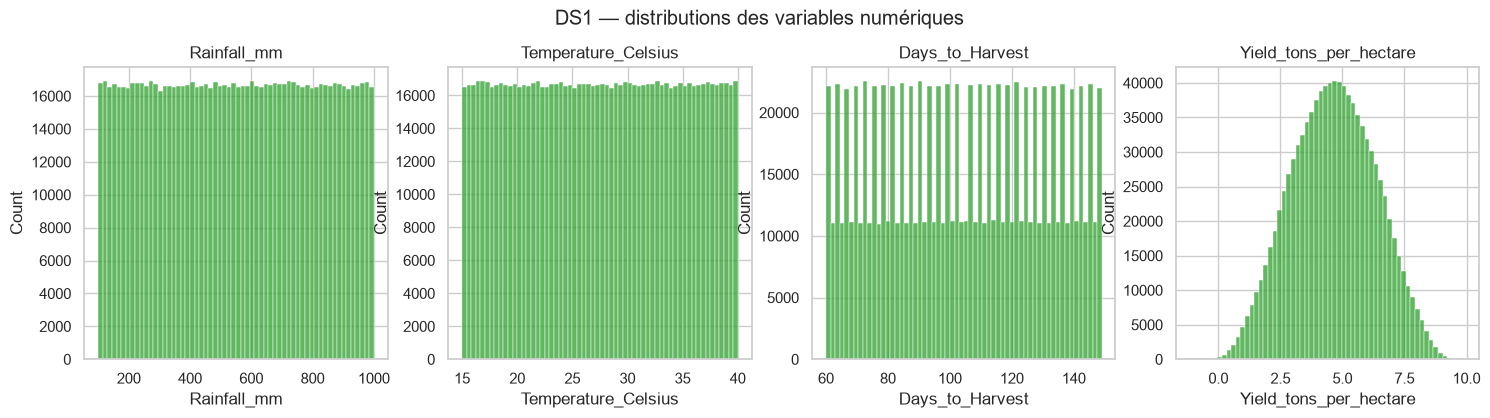

In [5]:
num_cols = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest", TARGET]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col in zip(axes, num_cols):
    sns.histplot(ds1_raw[col], bins=60, ax=ax, color="tab:green")
    ax.set_title(col)
plt.suptitle("DS1 — distributions des variables numériques", y=1.03)
plt.show()

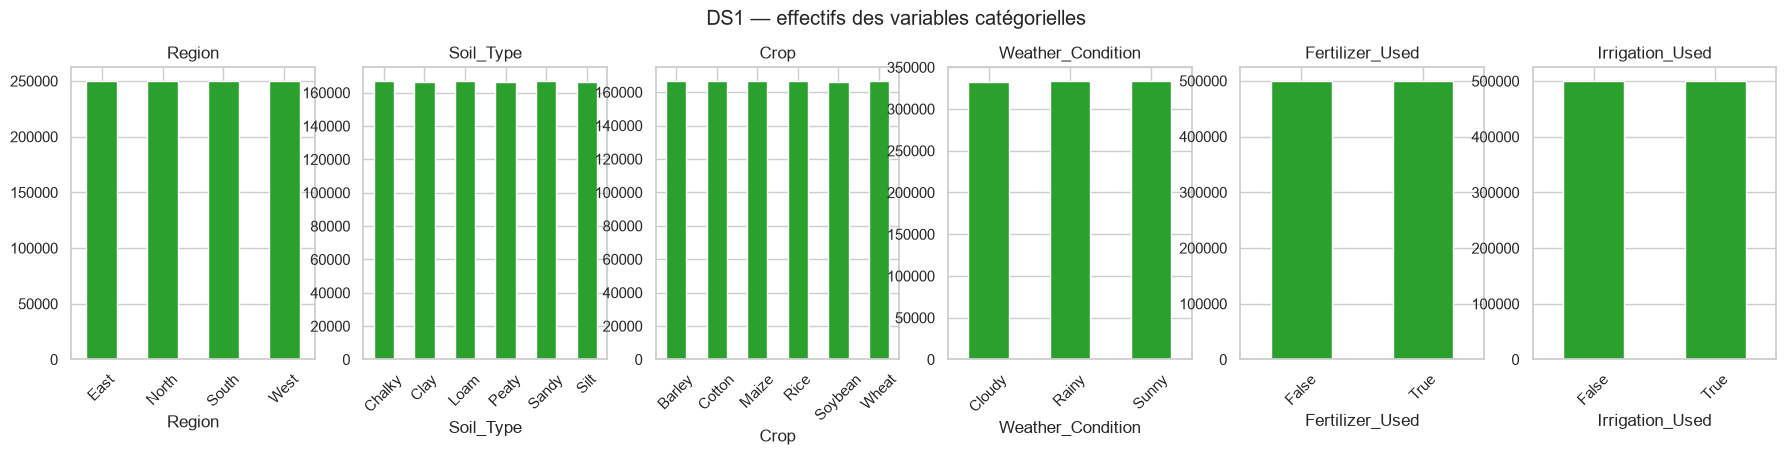

In [6]:
cat_cols = ["Region", "Soil_Type", "Crop", "Weather_Condition", "Fertilizer_Used", "Irrigation_Used"]
fig, axes = plt.subplots(1, 6, figsize=(22, 3.8))
for ax, col in zip(axes, cat_cols):
    ds1_raw[col].value_counts().sort_index().plot.bar(ax=ax, color="tab:green")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
plt.suptitle("DS1 — effectifs des variables catégorielles", y=1.03)
plt.show()

**Constats :** pluie, température et durée de culture suivent des **lois uniformes** parfaites ; toutes les modalités sont **équiréparties**. Le rendement est quasi gaussien (moyenne 4,65 t/ha). Ce profil est typique d'un **jeu de données synthétique** : il faudra en tenir compte dans l'interprétation.

### 2.3 Rendements négatifs

In [7]:
neg = ds1_raw[ds1_raw[TARGET] <= 0]
print(f"{len(neg)} rendements <= 0 ({len(neg) / len(ds1_raw):.3%} des lignes)")
neg[["Rainfall_mm", "Fertilizer_Used", "Irrigation_Used", TARGET]].describe().T

231 rendements <= 0 (0.023% des lignes)


,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,231.000,134.831,28.681,100.298,111.273,129.660,148.135,235.792
Yield_tons_per_hectare,231.000,-0.196,0.194,-1.148,-0.264,-0.135,-0.055,-0.000


Un rendement négatif est **physiquement impossible**. Ces lignes cumulent pluie très faible (< 240 mm), sans engrais ni irrigation : c'est le bruit du générateur qui fait passer le rendement sous zéro. Elles représentent 0,02 % des données → **suppression** (impact négligeable, pas de biais).

### 2.4 Corrélations et facteurs du rendement

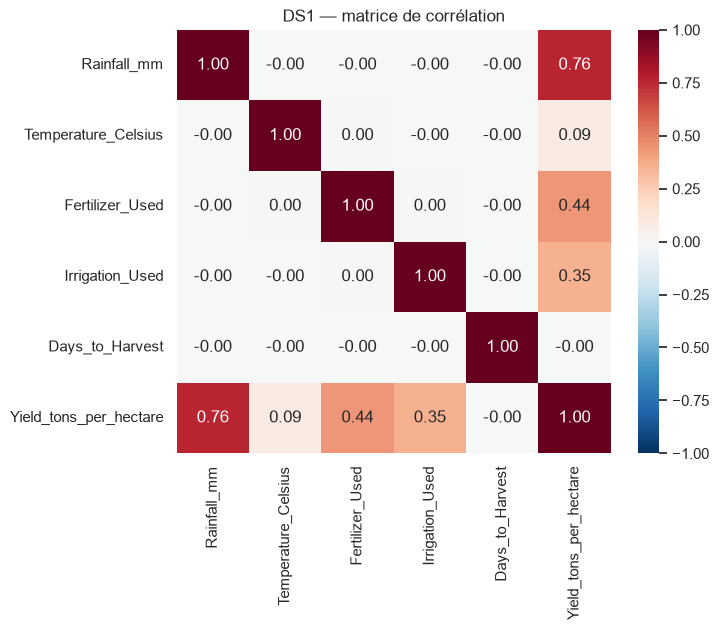

In [8]:
ds1_num = ds1_raw.select_dtypes(["number", "bool"]).astype(float)
plt.figure(figsize=(7, 5.5))
sns.heatmap(ds1_num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("DS1 — matrice de corrélation")
plt.show()

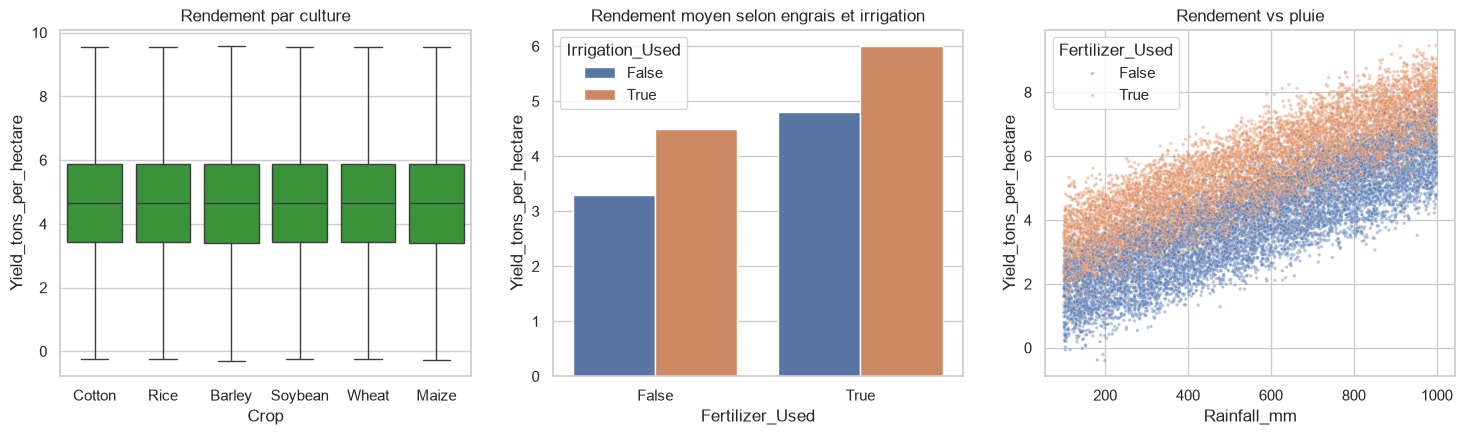

In [ ]:
# Visualisation des relations entre le rendement et les autres variables
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(data=ds1_raw, x="Crop", y=TARGET, ax=axes[0], color="tab:green", showfliers=False)
axes[0].set_title("Rendement par culture")
sns.barplot(data=ds1_raw, x="Fertilizer_Used", y=TARGET, hue="Irrigation_Used", ax=axes[1], errorbar=None)
axes[1].set_title("Rendement moyen selon engrais et irrigation")
s = ds1_raw.sample(SAMPLE, random_state=0)
sns.scatterplot(data=s, x="Rainfall_mm", y=TARGET, hue="Fertilizer_Used", s=6, alpha=0.4, ax=axes[2])
axes[2].set_title("Rendement vs pluie")
plt.show()

In [ ]:
# Régression linéaire simple, pour identifier les variables les plus corrélées au rendement
X = pd.get_dummies(
    ds1_raw.drop(columns=TARGET), columns=["Region", "Soil_Type", "Crop", "Weather_Condition"], drop_first=True
).astype(float)
lin = LinearRegression().fit(X, ds1_raw[TARGET])
print(f"R² d'une simple régression linéaire : {lin.score(X, ds1_raw[TARGET]):.3f}")
pd.Series(lin.coef_, index=X.columns, name="coefficient (t/ha par unité)").sort_values(key=abs, ascending=False).to_frame()

R² d'une simple régression linéaire : 0.913


,coefficient (t/ha par unité)
Fertilizer_Used,1.500
Irrigation_Used,1.200
Temperature_Celsius,0.020
Rainfall_mm,0.005
Soil_Type_Clay,0.004
Crop_Maize,-0.003
Crop_Wheat,-0.003
Soil_Type_Sandy,0.002
Weather_Condition_Rainy,0.001
Region_West,-0.001


**Constat majeur :** une régression linéaire explique **91 %** de la variance. Le rendement DS1 suit quasiment la formule :

> rendement ≈ 0,005 × pluie (mm) + 0,02 × température (°C) + 1,5 × engrais + 1,2 × irrigation + bruit

- **Variables clés DS1 :** pluie (r = 0,77), engrais (+1,5 t/ha), irrigation (+1,2 t/ha), température (effet faible).
- **Sans effet :** culture, type de sol, région, météo, durée de culture (coefficients ≈ 0).

⚠️ **La culture n'a aucun effet sur le rendement** (4,65 t/ha pour toutes). Un modèle entraîné sur DS1 seul donnerait le même rendement pour toutes les cultures : la **fonction de recommandation serait inutile**. C'est DS2 qui doit apporter le signal propre à chaque culture.

## 3. Exploration de DS2 — Crop Yield Prediction (FAO)

`yield_df.csv` est la version déjà jointe des fichiers bruts FAO / Banque mondiale (`yield.csv`, `pesticides.csv`, `rainfall.csv`, `temp.csv`). Nous l'utilisons comme base, après avoir contrôlé sa construction.

### 3.1 Structure, types et valeurs manquantes

In [11]:
overview(ds2_raw)

,type,manquants,% manquants,valeurs uniques,exemple
Area,str,0,0.000,101,Albania
Item,str,0,0.000,10,Maize
Year,int64,0,0.000,23,1990
hg/ha_yield,int64,0,0.000,11514,36613
average_rain_fall_mm_per_year,float64,0,0.000,100,"1,485.000"
pesticides_tonnes,float64,0,0.000,1673,121.000
avg_temp,float64,0,0.000,1831,16.370


In [12]:
raw_dir = prep.DS2_PATH.parent
rain_raw = pd.read_csv(raw_dir / "rainfall.csv")
temp_raw = pd.read_csv(raw_dir / "temp.csv")
print("rainfall.csv colonnes :", rain_raw.columns.tolist(), "(espace parasite devant 'Area')")
rain_num = pd.to_numeric(rain_raw["average_rain_fall_mm_per_year"], errors="coerce")
print(f"rainfall.csv : {rain_num.isna().sum()} valeurs manquantes ou '..' sur {len(rain_raw)}")
print(f"temp.csv     : {temp_raw['avg_temp'].isna().sum()} températures manquantes sur {len(temp_raw)}")
print(f"temp.csv     : {temp_raw.groupby(['country', 'year']).size().gt(1).sum():,} couples (pays, année) avec plusieurs relevés")

rainfall.csv colonnes : [' Area', 'Year', 'average_rain_fall_mm_per_year'] (espace parasite devant 'Area')
rainfall.csv : 780 valeurs manquantes ou '..' sur 6727
temp.csv     : 2547 températures manquantes sur 71311
temp.csv     : 7,994 couples (pays, année) avec plusieurs relevés


`yield_df.csv` ne contient **aucune valeur manquante** : les lignes incomplètes des fichiers bruts (pluie notée `..`, températures absentes) ont été exclues lors de la jointure d'origine, qui ne garde que les pays et années présents dans les quatre sources. En revanche, `temp.csv` contient **plusieurs relevés par pays et par an** (une ligne par station), ce qui a des conséquences ci-dessous.

### 3.2 Doublons et artefact de granularité

In [13]:
print(f"Doublons exacts : {ds2_raw.duplicated().sum():,}")
dedup = ds2_raw.drop_duplicates()
per_key = dedup.groupby(["Area", "Item", "Year"]).agg(
    lignes=("avg_temp", "size"), rendements_distincts=("hg/ha_yield", "nunique"), temperatures_distinctes=("avg_temp", "nunique")
)
print(f"(pays, culture, année) répétés : {(per_key['lignes'] > 1).sum():,} sur {len(per_key):,}")
print("Rendements distincts au sein d'une même clé :", per_key["rendements_distincts"].unique())
dedup[(dedup["Area"] == "India") & (dedup["Item"] == "Maize") & (dedup["Year"] == 1990)].head(6)

Doublons exacts : 2,310
(pays, culture, année) répétés : 3,690 sur 13,130
Rendements distincts au sein d'une même clé : [1]


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
10524,India,Maize,1990,15178,"1,083.000","75,000.000",25.580
10525,India,Maize,1990,15178,"1,083.000","75,000.000",26.880
10526,India,Maize,1990,15178,"1,083.000","75,000.000",25.790
10527,India,Maize,1990,15178,"1,083.000","75,000.000",24.100
10528,India,Maize,1990,15178,"1,083.000","75,000.000",25.250
10529,India,Maize,1990,15178,"1,083.000","75,000.000",25.440


In [14]:
by_area_year = dedup.groupby(["Area", "Year"])
print("Pesticides différents entre cultures d'un même (pays, année) :", by_area_year["pesticides_tonnes"].nunique().gt(1).sum())
print("Pluie différente entre cultures d'un même (pays, année)      :", by_area_year["average_rain_fall_mm_per_year"].nunique().gt(1).sum())

Pesticides différents entre cultures d'un même (pays, année) : 0
Pluie différente entre cultures d'un même (pays, année)      : 0


**Constats :**
- **2 310 doublons exacts** à supprimer.
- Au-delà, chaque rendement est **répété autant de fois que le pays a de stations météo** (ex. Inde : 22 lignes par an, même rendement, températures différentes). C'est un artefact de la jointure avec `temp.csv` qui surpondère artificiellement les grands pays. **Correction : une ligne par (pays, culture, année), température moyennée.**
- Pluie et **pesticides sont des indicateurs nationaux** : identiques pour toutes les cultures d'un pays une année donnée. Les pesticides sont des **tonnes totales par pays**, pas des doses par hectare.

In [15]:
fao = (
    dedup.groupby(["Area", "Item", "Year"], as_index=False)
    .agg(yield_t_ha=("hg/ha_yield", "first"), rainfall_mm=("average_rain_fall_mm_per_year", "first"),
         pesticides_tonnes=("pesticides_tonnes", "first"), avg_temp=("avg_temp", "mean"))
)
fao["yield_t_ha"] /= prep.HG_PER_TONNE
print(f"FAO après correction : {len(fao):,} lignes (contre {len(ds2_raw):,} au départ), "
      f"{fao['Area'].nunique()} pays, {fao['Item'].nunique()} cultures, {fao['Year'].min()}-{fao['Year'].max()}")

FAO après correction : 13,130 lignes (contre 28,242 au départ), 101 pays, 10 cultures, 1990-2013

### 3.3 Distributions

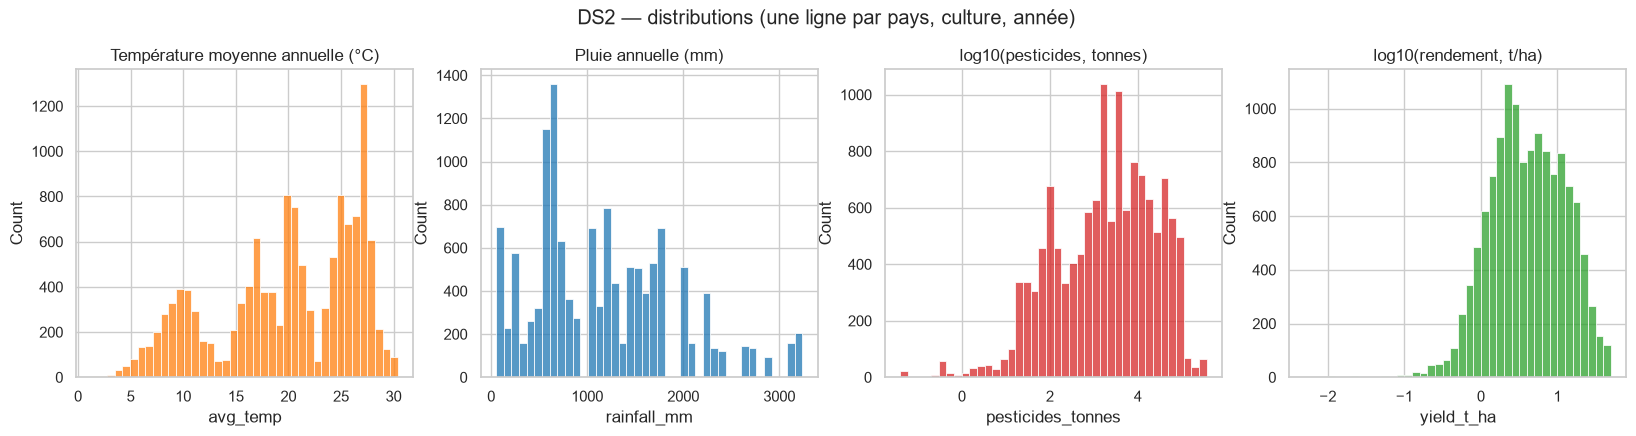

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.histplot(fao["avg_temp"], bins=40, ax=axes[0], color="tab:orange").set_title("Température moyenne annuelle (°C)")
sns.histplot(fao["rainfall_mm"], bins=40, ax=axes[1], color="tab:blue").set_title("Pluie annuelle (mm)")
sns.histplot(np.log10(fao["pesticides_tonnes"]), bins=40, ax=axes[2], color="tab:red").set_title("log10(pesticides, tonnes)")
sns.histplot(np.log10(fao["yield_t_ha"]), bins=40, ax=axes[3], color="tab:green").set_title("log10(rendement, t/ha)")
plt.suptitle("DS2 — distributions (une ligne par pays, culture, année)", y=1.03)
plt.show()

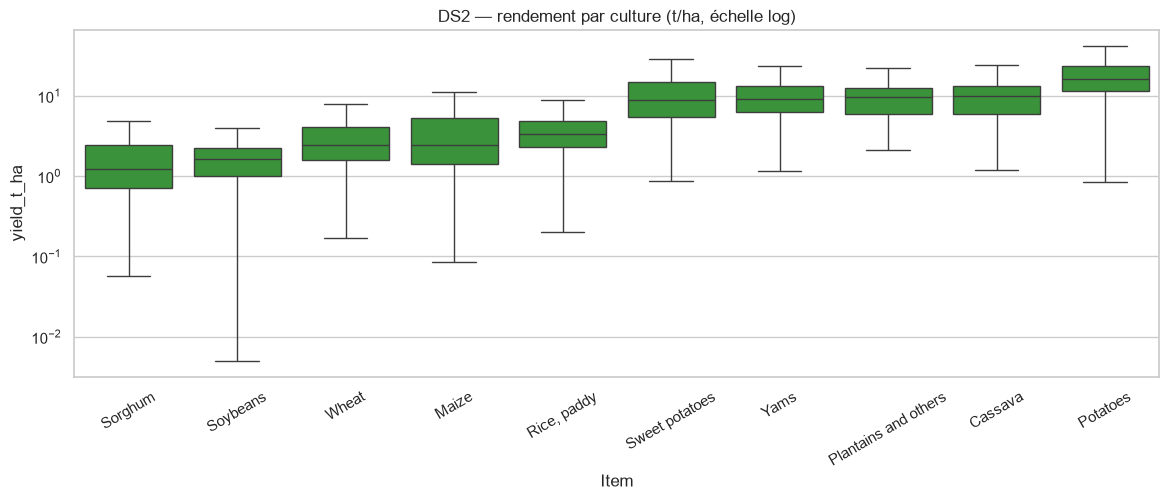

In [ ]:
# Visualisation des rendements par culture, pour identifier les cultures les plus et les moins productives
order = fao.groupby("Item")["yield_t_ha"].median().sort_values().index
plt.figure(figsize=(14, 4.5))
sns.boxplot(data=fao, x="Item", y="yield_t_ha", order=order, color="tab:green", showfliers=False)
plt.yscale("log")
plt.title("DS2 — rendement par culture (t/ha, échelle log)")
plt.xticks(rotation=30)
plt.show()

**Constats :** distributions réelles, asymétriques. Les pesticides s'étalent sur **7 ordres de grandeur** (taille des pays) → transformation logarithmique nécessaire en modélisation. Contrairement à DS1, **le rendement dépend fortement de la culture** : de ~1,5 t/ha (soja, sorgho) à ~18 t/ha (pomme de terre).

### 3.4 Corrélations et facteurs du rendement

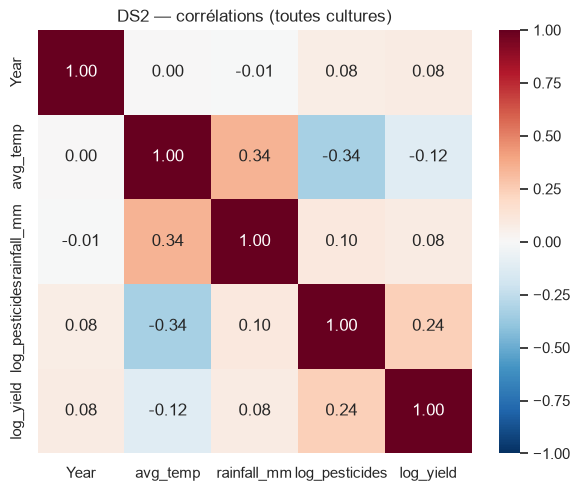

In [18]:
corr_df = fao.assign(log_pesticides=np.log10(fao["pesticides_tonnes"]), log_yield=np.log10(fao["yield_t_ha"]))
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_df[["Year", "avg_temp", "rainfall_mm", "log_pesticides", "log_yield"]].corr(),
            annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("DS2 — corrélations (toutes cultures)")
plt.show()

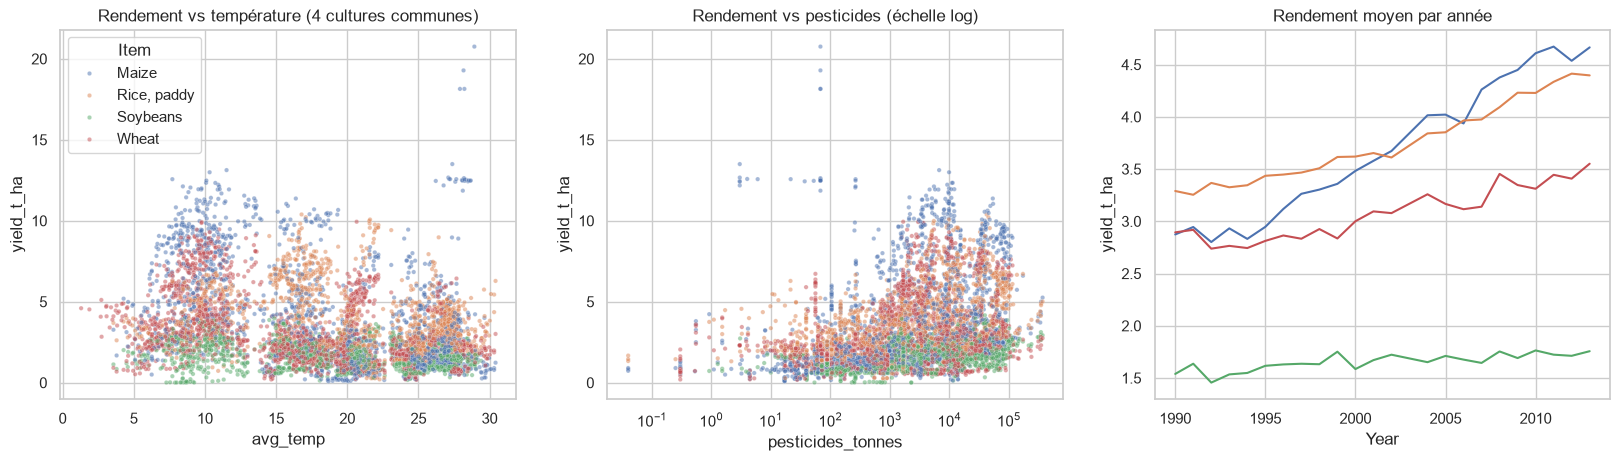

In [ ]:
# Visualisation des relations entre le rendement et les autres variables, pour les cultures communes aux deux datasets
common_fao = fao[fao["Item"].isin(prep.CROP_MAPPING)]
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
sns.scatterplot(data=common_fao, x="avg_temp", y="yield_t_ha", hue="Item", s=10, alpha=0.5, ax=axes[0])
axes[0].set_title("Rendement vs température (4 cultures communes)")
sns.scatterplot(data=common_fao, x="pesticides_tonnes", y="yield_t_ha", hue="Item", s=10, alpha=0.5, ax=axes[1], legend=False)
axes[1].set_xscale("log")
axes[1].set_title("Rendement vs pesticides (échelle log)")
sns.lineplot(data=common_fao, x="Year", y="yield_t_ha", hue="Item", ax=axes[2], errorbar=None, legend=False)
axes[2].set_title("Rendement moyen par année")
plt.show()

**Constats (données réelles) :**
- **Culture** : facteur dominant.
- **Température** : relation négative — les pays chauds (tropicaux) ont des rendements plus faibles en céréales.
- **Pesticides** : relation positive (r ≈ 0,38 en log pour les 4 cultures communes) — marqueur d'une agriculture intensive.
- **Pluie** : relation faible et non linéaire (l'irrigation compense la sécheresse, cf. §4.4).
- **Année** : légère tendance haussière (progrès technique), modeste sur 1990-2013.

### 3.5 Valeurs extrêmes

In [20]:
for crop in prep.CROP_MAPPING:
    s = common_fao[common_fao["Item"] == crop]
    top = s.nlargest(3, "yield_t_ha")[["Area", "Year", "yield_t_ha"]].to_records(index=False).tolist()
    print(f"{crop:12s} P99 = {s['yield_t_ha'].quantile(0.99):5.2f} t/ha | max : {top}")

Maize        P99 = 12.46 t/ha | max : [('Qatar', 2010, 20.7556), ('Qatar', 2009, 19.2857), ('Qatar', 2007, 18.1429)]
Rice, paddy  P99 =  9.39 t/ha | max : [('Australia', 2010, 10.3895), ('Australia', 2013, 10.2177), ('Egypt', 2006, 10.075)]
Soybeans     P99 =  3.65 t/ha | max : [('Turkey', 2013, 4.1609), ('Turkey', 2006, 3.9688), ('Switzerland', 2000, 3.9391)]
Wheat        P99 =  8.82 t/ha | max : [('Zambia', 2008, 9.9387), ('Ireland', 2004, 9.9241), ('Ireland', 2011, 9.8641)]


Le maïs du **Qatar** (18-21 t/ha) correspond à de micro-surfaces irriguées non représentatives d'une exploitation ; les autres extrêmes sont plausibles (riz australien et égyptien irrigué, blé irlandais). Plutôt que de supprimer des observations, nous **plafonnons les rendements au 99ᵉ percentile de chaque culture** (winsorisation).

## 4. Cohérence entre les deux sources

### 4.1 Cultures communes

In [21]:
ds1_crops = set(ds1_raw["Crop"].unique())
mapping = pd.DataFrame({"Nom FAO (DS2)": fao["Item"].unique()})
mapping["Nom DS1"] = mapping["Nom FAO (DS2)"].map(prep.CROP_MAPPING)
mapping["Présente dans les deux"] = mapping["Nom DS1"].notna()
print("Cultures DS1 absentes de la FAO :", sorted(ds1_crops - set(prep.CROP_MAPPING.values())))
mapping.sort_values("Présente dans les deux", ascending=False)

Cultures DS1 absentes de la FAO : ['Barley', 'Cotton']


,Nom FAO (DS2),Nom DS1,Présente dans les deux
0,Maize,Maize,True
2,"Rice, paddy",Rice,True
4,Soybeans,Soybean,True
5,Wheat,Wheat,True
1,Potatoes,NaN,False
3,Sorghum,NaN,False
6,Cassava,NaN,False
7,Sweet potatoes,NaN,False
8,Plantains and others,NaN,False
9,Yams,NaN,False


Seules **4 cultures** sont communes après harmonisation des libellés : *Maize*, *Rice, paddy* → *Rice*, *Soybeans* → *Soybean*, *Wheat*. L'orge (*Barley*) et le coton (*Cotton*) n'ont aucun équivalent FAO : sans référence réelle, et puisque DS1 ne distingue pas les cultures, il serait impossible de leur attribuer un rendement propre. **Le périmètre retenu est donc celui des 4 cultures communes** (666 000 parcelles, largement suffisant).

### 4.2 Unités et échelles

In [22]:
ranges = pd.DataFrame({
    "DS1 (parcelle)": [f"{ds1_raw['Temperature_Celsius'].min():.0f} – {ds1_raw['Temperature_Celsius'].max():.0f}",
                       f"{ds1_raw['Rainfall_mm'].min():.0f} – {ds1_raw['Rainfall_mm'].max():.0f}",
                       "t/ha", "absent", "Fertilizer_Used / Irrigation_Used (oui/non)"],
    "DS2 (pays, FAO)": [f"{fao['avg_temp'].min():.1f} – {fao['avg_temp'].max():.1f} (moyenne annuelle)",
                        f"{fao['rainfall_mm'].min():.0f} – {fao['rainfall_mm'].max():.0f} (cumul annuel)",
                        "hg/ha (1 t/ha = 10 000 hg/ha)", "tonnes totales par pays", "absent"],
}, index=["Température (°C)", "Pluie (mm)", "Rendement", "Pesticides", "Pratiques culturales"])
ranges

,DS1 (parcelle),"DS2 (pays, FAO)"
Température (°C),15 – 40,1.3 – 30.4 (moyenne annuelle)
Pluie (mm),100 – 1000,51 – 3240 (cumul annuel)
Rendement,t/ha,hg/ha (1 t/ha = 10 000 hg/ha)
Pesticides,absent,tonnes totales par pays
Pratiques culturales,Fertilizer_Used / Irrigation_Used (oui/non),absent


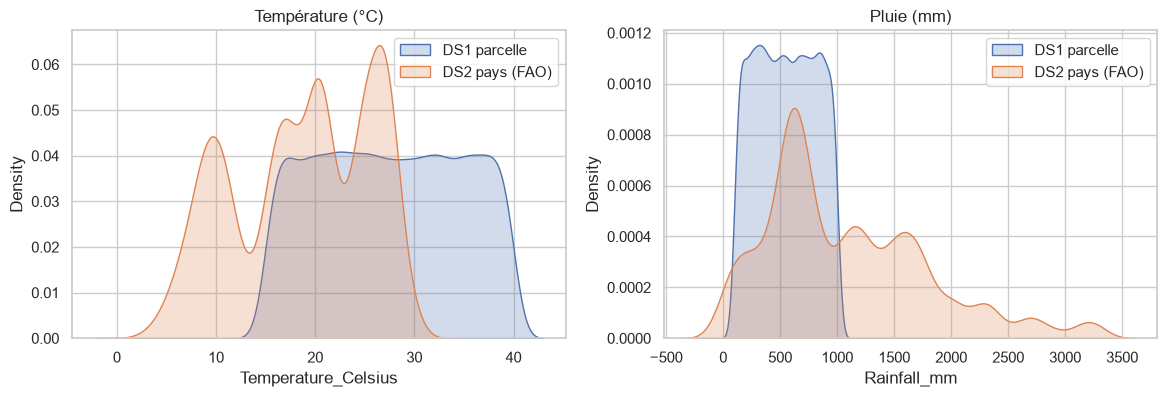

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (c1, c2, label) in zip(axes, [("Temperature_Celsius", "avg_temp", "Température (°C)"), ("Rainfall_mm", "rainfall_mm", "Pluie (mm)")]):
    sns.kdeplot(ds1_raw[c1].sample(SAMPLE, random_state=0), ax=ax, label="DS1 parcelle", fill=True)
    sns.kdeplot(common_fao[c2], ax=ax, label="DS2 pays (FAO)", fill=True)
    ax.set_title(label)
    ax.legend()
plt.show()

**Incohérence d'échelle :** DS1 décrit le climat **de la parcelle pendant la saison** (jusqu'à 40 °C, aucune moyenne annuelle nationale n'atteint cette valeur) ; DS2 des **moyennes annuelles nationales**. Comparer directement 35 °C (DS1) à 35 °C (FAO) n'a pas de sens.

**Choix :** aligner les deux échelles par **correspondance de quantiles** — une parcelle parmi les 10 % les plus chaudes de DS1 est rapprochée des pays parmi les 10 % les plus chauds de la FAO. Les autres conversions : rendement hg/ha → **t/ha**, booléens → **0/1**.

### 4.3 Clés de jointure

| Clé potentielle | DS1 | DS2 | Utilisable ? |
|---|---|---|---|
| Pays (`Area`) | ❌ (seulement 4 régions cardinales) | ✅ 101 pays | Non |
| Année (`Year`) | ❌ | ✅ 1990-2013 | Non |
| Culture (`Crop` / `Item`) | ✅ | ✅ | **Oui, exacte** après harmonisation |
| Climat (température, pluie) | ✅ | ✅ | **Oui, approchée** après alignement d'échelle |

Aucune clé n'identifie une même parcelle dans les deux sources : une jointure exacte (`merge` sur pays-année) est **impossible**. La fusion repose donc sur la **culture (exacte)** et le **climat (par proximité)** : c'est un problème d'**appariement statistique** (*statistical matching*).

### 4.4 Variables proxy : fertilisation et irrigation

In [24]:
arid = common_fao[common_fao["rainfall_mm"] < 250].groupby(["Area", "Item"])["yield_t_ha"].median().sort_values(ascending=False)
print("Pays arides (< 250 mm/an) — rendement médian (t/ha) :")
arid.head(8).to_frame()

Pays arides (< 250 mm/an) — rendement médian (t/ha) :


yield_t_ha
Area         Item                   
Qatar        Maize            12.530
Egypt        Rice, paddy       9.283
             Maize             7.517
             Wheat             6.347
Saudi Arabia Wheat             4.888
Mauritania   Rice, paddy       4.060
Saudi Arabia Maize             3.730
Montenegro   Maize             3.697

In [25]:
r = np.corrcoef(np.log(common_fao["pesticides_tonnes"]), np.log(common_fao["yield_t_ha"]))[0, 1]
print(f"Corrélation log(pesticides) / log(rendement), 4 cultures communes : r = {r:.2f}")
print(f"DS1 : effet moyen de l'engrais {ds1_raw.groupby('Fertilizer_Used')[TARGET].mean().diff().iloc[-1]:+.2f} t/ha, "
      f"de l'irrigation {ds1_raw.groupby('Irrigation_Used')[TARGET].mean().diff().iloc[-1]:+.2f} t/ha")

Corrélation log(pesticides) / log(rendement), 4 cultures communes : r = 0.38
DS1 : effet moyen de l'engrais +1.50 t/ha, de l'irrigation +1.20 t/ha


La FAO ne renseigne ni la fertilisation ni l'irrigation ; DS1 ne renseigne pas les pesticides. Proxys identifiés :

- **Pesticides → proxy d'intensification (fertilisation)** : engrais et produits phytosanitaires vont de pair dans l'agriculture intensive. Le lien positif pesticides / rendement côté FAO (r ≈ 0,38) joue le même rôle que `Fertilizer_Used` côté DS1 (+1,5 t/ha).
- **Rendement élevé malgré une pluie très faible → proxy d'irrigation** : l'Égypte (51 mm/an) produit ~9 t/ha de riz, ce qui n'est possible qu'avec une irrigation intégrale. C'est l'équivalent réel de `Irrigation_Used`, et la raison pour laquelle la pluie seule explique mal le rendement FAO.

Dans le dataset consolidé, `Fertilizer_Used` et `Irrigation_Used` (DS1) décrivent directement les pratiques de la parcelle, et `Pesticides_tonnes` (DS2) apporte l'indicateur d'intensification.

## 5. Stratégie de fusion

### 5.1 Options envisagées

| Option | Principe | Limite |
|---|---|---|
| Jointure sur la culture avec agrégats FAO | une moyenne FAO par culture ajoutée à chaque ligne DS1 | constantes par culture : information redondante avec `Crop`, et le rendement DS1 reste identique pour toutes les cultures |
| DS1 seul comme cible | enrichir DS1 de pesticides, garder son rendement | recommandation plate (toutes les cultures se valent) |
| FAO comme base | données réelles enrichies des effets DS1 | inverse le sens d'enrichissement demandé, 6 500 lignes seulement |
| **Appariement hot-deck (retenu)** | chaque parcelle DS1 reçoit un donneur FAO de même culture au climat proche | cible construite : hypothèse multiplicative à documenter |

### 5.2 Méthode retenue : appariement statistique par donneur (*distance hot-deck*)

Pour chaque parcelle DS1 :
1. **Alignement climatique** : température et pluie sont converties sur l'échelle FAO par correspondance de quantiles.
2. **Recherche des donneurs** : parmi les observations FAO (pays × année) **de la même culture**, on retient les **10 plus proches voisins** climatiques (distance euclidienne standardisée).
3. **Tirage d'un donneur** parmi ces 10 (graine fixe = 42, reproductible). Le tirage, plutôt qu'une moyenne, préserve la variabilité réelle des rendements et des pesticides.
4. **Enrichissement** : la parcelle hérite des **pesticides** du donneur.
5. **Rendement cible** :

$$\text{rendement} = \underbrace{\text{rendement FAO du donneur}}_{\text{potentiel culture} \times \text{climat (réel)}} \times \underbrace{\frac{\text{rendement DS1}}{\text{rendement DS1 attendu au même climat}}}_{\text{coefficient de conduite (engrais, irrigation, aléa)}}$$

Le coefficient de conduite vaut 1 en moyenne. Il retire de DS1 l'effet du climat (déjà apporté par le donneur FAO, pour ne pas compter la pluie deux fois) et ne conserve que l'effet des **pratiques culturales**. C'est l'approche agronomique classique « rendement potentiel × coefficient de conduite ».

### 5.3 Nettoyage avant fusion

In [26]:
ds1 = prep.clean_ds1(ds1_raw)
ds2 = prep.clean_ds2(ds2_raw)
print(f"DS1 : {len(ds1_raw):,} -> {len(ds1):,} lignes (4 cultures communes, rendements > 0)")
print(f"DS2 : {len(ds2_raw):,} -> {len(ds2):,} lignes (doublons, artefact de granularité, 4 cultures, plafonnement P99)")
ds2.head()

DS1 : 1,000,000 -> 666,494 lignes (4 cultures communes, rendements > 0)
DS2 : 28,242 -> 6,582 lignes (doublons, artefact de granularité, 4 cultures, plafonnement P99)


,Area,Year,rainfall_mm,pesticides_tonnes,avg_temp,Crop,yield_t_ha
0,Albania,1990,"1,485.000",121.000,16.370,Maize,3.661
1,Albania,1991,"1,485.000",121.000,15.360,Maize,2.907
2,Albania,1992,"1,485.000",121.000,16.060,Maize,2.488
3,Albania,1993,"1,485.000",121.000,16.050,Maize,2.418
4,Albania,1994,"1,485.000",201.000,16.960,Maize,2.585


### 5.4 Coefficient de conduite

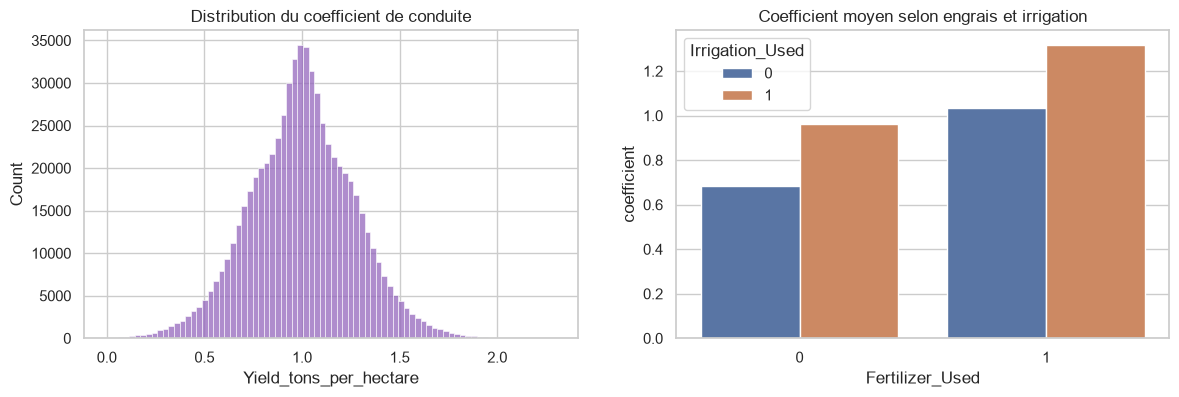

coefficient moyen
Fertilizer_Used Irrigation_Used                   
0               0                            0.683
                1                            0.964
1               0                            1.035
                1                            1.317

In [27]:
factor = prep.management_factor(ds1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(factor, bins=80, ax=axes[0], color="tab:purple").set_title("Distribution du coefficient de conduite")
sns.barplot(x=ds1["Fertilizer_Used"], y=factor, hue=ds1["Irrigation_Used"], ax=axes[1], errorbar=None)
axes[1].set_title("Coefficient moyen selon engrais et irrigation")
axes[1].set_ylabel("coefficient")
plt.show()
factor.groupby([ds1["Fertilizer_Used"], ds1["Irrigation_Used"]]).mean().rename("coefficient moyen").to_frame()

Sans engrais ni irrigation, une parcelle produit environ **68 %** du rendement attendu à climat égal ; avec les deux, environ **132 %**. C'est cette information, issue de DS1, qui est transférée sur les rendements réels FAO.

### 5.5 Fusion et diagnostic de l'appariement

In [28]:
dataset, audit = prep.fuse(ds1_raw, ds2_raw)
print(f"Dataset consolidé : {dataset.shape[0]:,} lignes x {dataset.shape[1]} colonnes")
print(f"Donneurs FAO distincts utilisés : {audit.groupby(['donor_area', 'donor_year', 'Crop']).ngroups:,} sur {len(ds2):,}")
audit.head()

Dataset consolidé : 666,494 lignes x 11 colonnes
Donneurs FAO distincts utilisés : 6,581 sur 6,582


,Crop,ds1_yield,management_factor,donor_area,donor_year,donor_yield_t_ha,donor_temp,donor_rainfall,donor_distance
0,Rice,8.527,1.279,Ecuador,2013,3.821,20.303,"2,274.000",2.111
1,Soybean,6.518,0.986,Ecuador,2008,1.600,20.257,"2,274.000",2.168
2,Wheat,7.248,1.287,Burundi,1998,0.815,21.560,"1,274.000",0.279
3,Soybean,5.898,0.969,Thailand,1994,1.334,27.760,"1,622.000",0.079
4,Wheat,2.652,0.703,Zimbabwe,1991,5.891,20.950,657.000,0.240


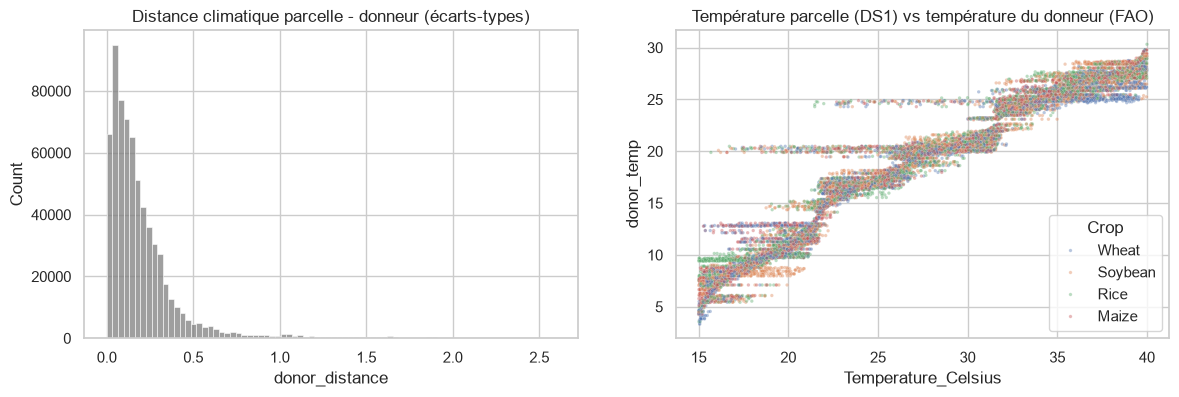

count   666,494.000
mean          0.211
std           0.262
min           0.000
50%           0.140
90%           0.414
99%           1.521
max           2.592
Name: donor_distance, dtype: float64


In [ ]:
# Visualisation des distances climatiques entre parcelle et donneur FAO, et comparaison des températures
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(audit["donor_distance"], bins=80, ax=axes[0], color="tab:gray")
axes[0].set_title("Distance climatique parcelle - donneur (écarts-types)")
s = audit.sample(SAMPLE, random_state=0).assign(Temperature_Celsius=ds1["Temperature_Celsius"])
sns.scatterplot(data=s, x="Temperature_Celsius", y="donor_temp", hue="Crop", s=6, alpha=0.4, ax=axes[1])
axes[1].set_title("Température parcelle (DS1) vs température du donneur (FAO)")
plt.show()
print(audit["donor_distance"].describe(percentiles=[0.5, 0.9, 0.99]).round(3))

**Qualité de l'appariement :** l'écart climatique médian entre une parcelle et son donneur est de **0,14 écart-type**, et 90 % des parcelles sont à moins de 0,41. Environ 1 % dépassent 1,5 écart-type : ce sont des climats où la culture est rare dans les données FAO (ex. riz en climat frais et très humide) ; le donneur retenu reste alors le plus proche disponible. La relation croissante entre la température de la parcelle et celle du donneur confirme que l'alignement par quantiles préserve l'ordre climatique. 6 581 des 6 582 observations FAO servent de donneur : la diversité réelle est conservée.

## 6. Validation du dataset consolidé

In [30]:
print("Valeurs manquantes :", dataset.isna().sum().sum(), "| doublons :", dataset.duplicated().sum())
overview(dataset)

Valeurs manquantes : 0 | doublons : 0


,type,manquants,% manquants,valeurs uniques,exemple
Region,str,0,0.000,4,South
Soil_Type,str,0,0.000,6,Clay
Crop,str,0,0.000,4,Rice
Rainfall_mm,float64,0,0.000,89945,992.670
Temperature_Celsius,float64,0,0.000,2501,18.030
Pesticides_tonnes,float64,0,0.000,1654,"6,471.770"
Fertilizer_Used,int64,0,0.000,2,1
Irrigation_Used,int64,0,0.000,2,1
Weather_Condition,str,0,0.000,3,Rainy
Days_to_Harvest,int64,0,0.000,90,140


In [31]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,"666,494.000",550.196,259.735,100.010,325.303,550.710,774.678,"1,000.000"
Temperature_Celsius,"666,494.000",27.501,7.218,15.000,21.250,27.500,33.740,40.000
Pesticides_tonnes,"666,494.000","13,913.185","28,855.577",0.040,470.870,"3,269.990","14,216.000","367,778.000"
Fertilizer_Used,"666,494.000",0.500,0.500,0.000,0.000,1.000,1.000,1.000
Irrigation_Used,"666,494.000",0.500,0.500,0.000,0.000,0.000,1.000,1.000
Days_to_Harvest,"666,494.000",104.503,25.956,60.000,82.000,105.000,127.000,149.000
Yield_tons_per_hectare,"666,494.000",2.956,2.420,0.001,1.329,2.219,3.750,24.252


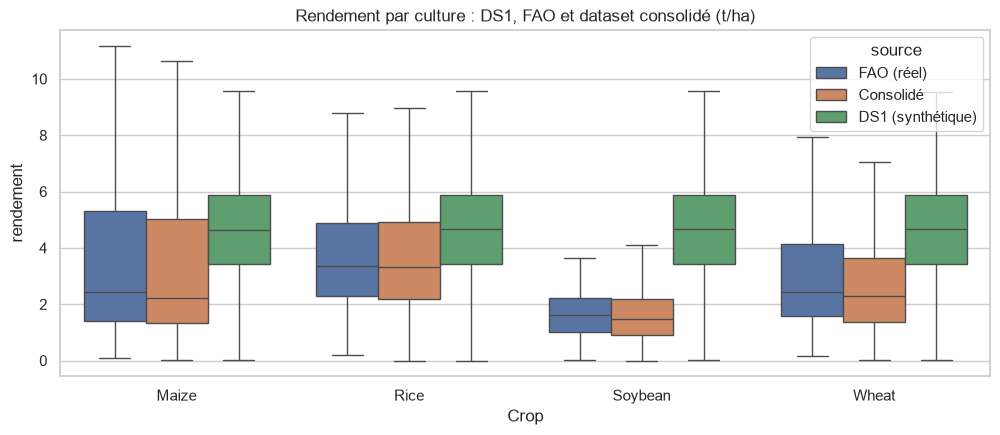

In [ ]:
# Visualisation des rendements par culture, pour comparer DS1, FAO et dataset consolidé
compare = pd.concat([
    ds2[["Crop", "yield_t_ha"]].rename(columns={"yield_t_ha": "rendement"}).assign(source="FAO (réel)"),
    dataset[["Crop", TARGET]].rename(columns={TARGET: "rendement"}).assign(source="Consolidé"),
    ds1[["Crop", TARGET]].rename(columns={TARGET: "rendement"}).assign(source="DS1 (synthétique)"),
])
plt.figure(figsize=(12, 4.5))
sns.boxplot(data=compare, x="Crop", y="rendement", hue="source", showfliers=False)
plt.title("Rendement par culture : DS1, FAO et dataset consolidé (t/ha)")
plt.show()

Le dataset consolidé **hérite des écarts réels entre cultures** que DS1 ignorait (médianes : soja 1,5 < maïs 2,2 ≈ blé 2,3 < riz 3,3 t/ha), avec une dispersion légèrement accrue par l'effet des pratiques culturales.

In [33]:
effects = pd.DataFrame({
    "DS1": ds1.groupby(["Fertilizer_Used", "Irrigation_Used"])[TARGET].mean(),
    "Consolidé": dataset.groupby(["Fertilizer_Used", "Irrigation_Used"])[TARGET].mean(),
})
(effects / effects.iloc[0]).rename(columns=lambda c: f"{c} (relatif à sans engrais ni irrigation)")

DS1 (relatif à sans engrais ni irrigation)  \
Fertilizer_Used Irrigation_Used                                               
0               0                                                     1.000   
                1                                                     1.362   
1               0                                                     1.451   
                1                                                     1.814   

                                 Consolidé (relatif à sans engrais ni irrigation)  
Fertilizer_Used Irrigation_Used                                                    
0               0                                                           1.000  
                1                                                           1.405  
1               0                                                           1.512  
                1                                                           1.907

Les **effets relatifs** de l'engrais et de l'irrigation sont préservés : leur impact en pourcentage est du même ordre dans DS1 et dans le dataset consolidé.

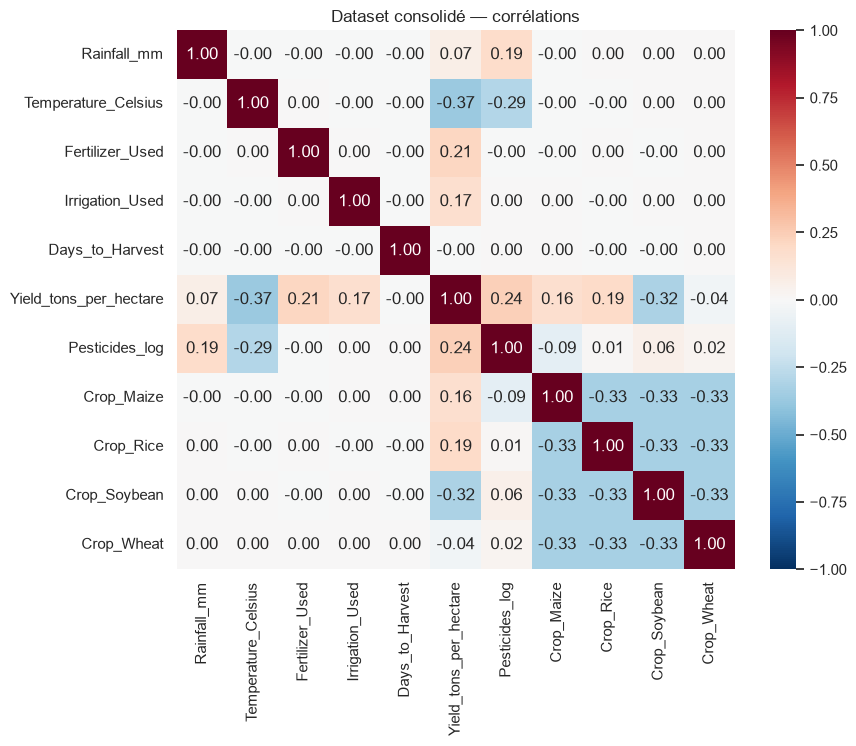

In [34]:
heat = dataset.assign(Pesticides_log=np.log10(dataset["Pesticides_tonnes"])).drop(columns="Pesticides_tonnes")
heat = pd.get_dummies(heat, columns=["Crop"], dtype=float).select_dtypes("number")
plt.figure(figsize=(9, 7))
sns.heatmap(heat.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Dataset consolidé — corrélations")
plt.show()

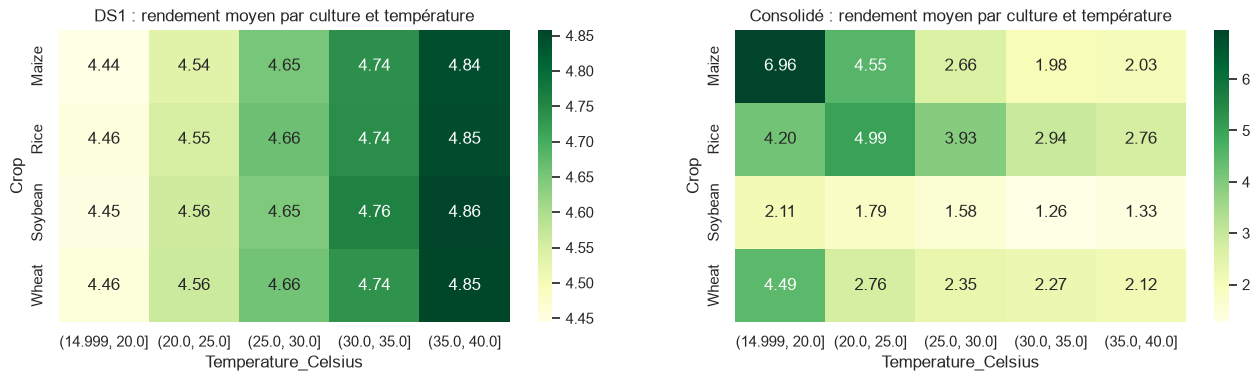

In [ ]:
# Visualisation des rendements par culture et température, pour comparer DS1 et dataset consolidé
t_bins = pd.cut(dataset["Temperature_Celsius"], [15, 20, 25, 30, 35, 40], include_lowest=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
sns.heatmap(ds1.pivot_table(TARGET, "Crop", pd.cut(ds1["Temperature_Celsius"], [15, 20, 25, 30, 35, 40], include_lowest=True), observed=True),
            annot=True, fmt=".2f", cmap="YlGn", ax=axes[0])
axes[0].set_title("DS1 : rendement moyen par culture et température")
sns.heatmap(dataset.pivot_table(TARGET, "Crop", t_bins, observed=True), annot=True, fmt=".2f", cmap="YlGn", ax=axes[1])
axes[1].set_title("Consolidé : rendement moyen par culture et température")
plt.show()

**Résultat clé pour la recommandation :** dans DS1, toutes les cultures ont le même rendement quelle que soit la température. Dans le dataset consolidé, **le classement des cultures varie selon le climat** : par temps frais (15-20 °C) le maïs arrive en tête (~7 t/ha), par forte chaleur (35-40 °C) c'est le riz (~2,8 t/ha). C'est exactement le signal dont le moteur de recommandation a besoin.

## 7. Export et dictionnaire des données

In [36]:
prep.OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
dataset.to_csv(prep.OUTPUT_PATH, index=False)
print(f"Exporté : {prep.OUTPUT_PATH.relative_to(ROOT)} ({prep.OUTPUT_PATH.stat().st_size / 1e6:.1f} Mo)")

Exporté : data\processed\dataset_consolide.csv (39.5 Mo)


| Colonne | Type | Source | Description |
|---|---|---|---|
| `Region` | catégorielle | DS1 | Région de la parcelle (North, South, East, West) |
| `Soil_Type` | catégorielle | DS1 | Type de sol (6 modalités) |
| `Crop` | catégorielle | DS1 + DS2 | Culture : Maize, Rice, Soybean, Wheat (clé d'appariement) |
| `Rainfall_mm` | numérique | DS1 | Pluie sur la parcelle (mm, 100-1000) |
| `Temperature_Celsius` | numérique | DS1 | Température sur la parcelle (°C, 15-40) |
| `Pesticides_tonnes` | numérique | DS2 | Usage de pesticides du pays donneur (tonnes de matière active) — proxy d'intensification |
| `Fertilizer_Used` | binaire 0/1 | DS1 | Engrais utilisé |
| `Irrigation_Used` | binaire 0/1 | DS1 | Irrigation utilisée |
| `Weather_Condition` | catégorielle | DS1 | Météo dominante (Sunny, Rainy, Cloudy) |
| `Days_to_Harvest` | numérique | DS1 | Durée de culture (jours, 60-149) |
| `Yield_tons_per_hectare` | numérique | DS1 × DS2 | **Cible** : rendement FAO du donneur × coefficient de conduite DS1 (t/ha) |

**Prétraitements laissés au pipeline d'entraînement** (pour éviter toute fuite de données entre jeux d'entraînement et de test) : encodage one-hot des catégorielles, transformation log et standardisation des pesticides et variables numériques. `Region`, `Soil_Type`, `Weather_Condition` et `Days_to_Harvest` sont conservées à ce stade : n'ayant montré aucun effet, leur exclusion sera confirmée par l'ACP de l'étape suivante.

## 8. Synthèse des choix et variables clés

**Nettoyage**
- DS1 : suppression de 231 rendements négatifs (0,02 %, physiquement impossibles) ; restriction aux 4 cultures présentes à la FAO (orge et coton sans référence réelle) ; booléens convertis en 0/1.
- DS2 : suppression de 2 310 doublons exacts et correction d'un artefact de jointure qui répétait chaque rendement par station météo (28 242 → 13 130 lignes réelles, 6 582 pour les 4 cultures) ; conversion hg/ha → t/ha ; harmonisation des noms de cultures ; plafonnement des rendements extrêmes au 99ᵉ percentile par culture.
- Aucune valeur manquante dans les fichiers utilisés ; les manquants des fichiers bruts FAO avaient déjà été exclus.

**Fusion** : aucune clé commune (pays, année) n'existe → appariement statistique par donneur sur la culture (exacte) et le climat (aligné par quantiles). Rendement cible = potentiel réel FAO (culture × climat) × coefficient de conduite DS1 (engrais, irrigation).

**Variables clés identifiées**
- **Culture** : premier facteur de rendement dans les données réelles (absent de DS1).
- **Engrais et irrigation** : environ +50 % (engrais) et +40 % (irrigation) de rendement ; les deux combinés presque doublent (×1,9) le rendement d'une parcelle non conduite.
- **Température** : effet négatif dans les données réelles (climats chauds moins productifs pour ces céréales).
- **Pesticides** : marqueur d'agriculture intensive, positivement lié au rendement.
- **Pluie** : déterminante dans DS1, mais compensée par l'irrigation dans les données réelles.
- **Sans effet** : type de sol, région, météo dominante, durée de culture.

**Limites à garder en tête** : DS1 est synthétique ; les pesticides FAO sont des totaux nationaux, pas des doses par hectare ; la cible repose sur l'hypothèse multiplicative potentiel × conduite.